## INSTALL THE PACKAGES

In [ ]:
!pip install tensorflow
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn
!pip install opencv-python
!pip install Pillow

## IMPORT LIBRARIES

In [ ]:
import os
import gc
import json
import random
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image, ImageFile

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

ImageFile.LOAD_TRUNCATED_IMAGES = False

sns.set_theme(style="whitegrid")

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## MOUNT THE DRIVE

> The colab is mounted with the drive so as to locate the dataset uploaded after it has been downloaded from Kaggle.



In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## LOCATE THE DATASET PATH

> We identify our actual structure before loading any images, this will help us to know the directory where our dataset is located.



In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/DATASET/PlantVillage.zip"

if os.path.isfile(ZIP_PATH):
    size_mb = os.path.getsize(ZIP_PATH) / (1024 ** 2)
    print("PlantVillage ZIP file found!")
    print(f"File size: {size_mb:.2f} MB")
else:
    raise FileNotFoundError(
        f"ZIP file not found: {ZIP_PATH}\n"
        "Ensure Google Drive is mounted."
    )

PlantVillage ZIP file found!
File size: 657.57 MB


## EXTRACT THE DATASET FROM THE DRIVE

> Extraction was done to separate the dataset file directory from any folder or sub-folder for easy identification and path copying.



In [ ]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/DATASET/PlantVillage.zip"
EXTRACT_DIR = "/content/PlantVillage"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    bad_file = zip_ref.testzip()

    if bad_file is not None:
        raise ValueError(f"Corrupted file detected: {bad_file}")

    total_files = len(zip_ref.namelist())
    print(f"ZIP verified. Files to extract: {total_files}")

    zip_ref.extractall(EXTRACT_DIR)

print("\nExtraction completed successfully!")
print("Extraction location:", EXTRACT_DIR)

ZIP verified. Files to extract: 41278

Extraction completed successfully!
Extraction location: /content/PlantVillage


## CHECK THE DATASET STRUCTURE

> We check the nature and structure of the dataset by knowing the number of images and as well the classes



In [ ]:

import os
from collections import Counter

ROOT_DIR = "/content/PlantVillage"

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

if not os.path.exists(ROOT_DIR):
    raise FileNotFoundError(
        "Dataset directory not found. Please check extraction."
    )

print("DATASET INSPECTION")
print("=" * 60)

total_images = 0
class_counts = Counter()
candidate_dirs = []

for current_root, dirs, files in os.walk(ROOT_DIR):
    image_files = [
        f for f in files
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    if image_files:
        total_images += len(image_files)

        # A directory containing images and no image files
        # directly inside its parent may represent a class folder.
        class_counts[os.path.basename(current_root)] += len(image_files)

        if dirs:
            candidate_dirs.append(current_root)

print("Total image files:", total_images)
print("Directories containing images:", len(class_counts))

print("\nIMAGE COUNTS BY IMAGE-CONTAINING DIRECTORY")
print("-" * 60)

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

print("\nPOSSIBLE PARENT DATASET DIRECTORIES")
for path in candidate_dirs:
    print(path)


DATASET INSPECTION
Total image files: 41276
Directories containing images: 15

IMAGE COUNTS BY IMAGE-CONTAINING DIRECTORY
------------------------------------------------------------
Pepper__bell___Bacterial_spot: 1994
Pepper__bell___healthy: 2956
Potato___Early_blight: 2000
Potato___Late_blight: 2000
Potato___healthy: 304
Tomato_Bacterial_spot: 4254
Tomato_Early_blight: 2000
Tomato_Late_blight: 3818
Tomato_Leaf_Mold: 1904
Tomato_Septoria_leaf_spot: 3542
Tomato_Spider_mites_Two_spotted_spider_mite: 3352
Tomato__Target_Spot: 2808
Tomato__Tomato_YellowLeaf__Curl_Virus: 6416
Tomato__Tomato_mosaic_virus: 746
Tomato_healthy: 3182

POSSIBLE PARENT DATASET DIRECTORIES


In [ ]:

import os

ROOT_DIR = "/content/PlantVillage"
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

print("DIRECTORIES CONTAINING IMAGES")
print("=" * 70)

total_images = 0
image_dirs = []

for current_root, dirs, files in os.walk(ROOT_DIR):
    images = [
        f for f in files
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    if images:
        image_dirs.append((current_root, len(images)))
        total_images += len(images)

for path, count in sorted(image_dirs):
    print(f"{count:6d} images | {path}")

print("\nTotal image-containing directories:", len(image_dirs))
print("Total images:", total_images)


DIRECTORIES CONTAINING IMAGES
   997 images | /content/PlantVillage/PlantVillage/Pepper__bell___Bacterial_spot
  1478 images | /content/PlantVillage/PlantVillage/Pepper__bell___healthy
  1000 images | /content/PlantVillage/PlantVillage/Potato___Early_blight
  1000 images | /content/PlantVillage/PlantVillage/Potato___Late_blight
   152 images | /content/PlantVillage/PlantVillage/Potato___healthy
  2127 images | /content/PlantVillage/PlantVillage/Tomato_Bacterial_spot
  1000 images | /content/PlantVillage/PlantVillage/Tomato_Early_blight
  1909 images | /content/PlantVillage/PlantVillage/Tomato_Late_blight
   952 images | /content/PlantVillage/PlantVillage/Tomato_Leaf_Mold
  1771 images | /content/PlantVillage/PlantVillage/Tomato_Septoria_leaf_spot
  1676 images | /content/PlantVillage/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite
  1404 images | /content/PlantVillage/PlantVillage/Tomato__Target_Spot
  3208 images | /content/PlantVillage/PlantVillage/Tomato__Tomato_YellowLeaf_

In [ ]:
from pathlib import Path

print("DATASET_ROOT:", DATASET_ROOT)
print("Does path exist?", DATASET_ROOT.exists())

print("\nImmediate folders:")
for p in sorted(DATASET_ROOT.iterdir()):
    if p.is_dir():
        image_count = sum(
            1 for f in p.rglob("*")
            if f.is_file() and f.suffix.lower()
            in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )
        print(f"{p.name}: {image_count} images")

DATASET_ROOT: /content/PlantVillage
Does path exist? True

Immediate folders:
PlantVillage: 20638 images
plantvillage: 20638 images


In [ ]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

print("Searching for possible class directories...\n")

for folder in [DATASET_ROOT, *DATASET_ROOT.rglob("*")]:
    if not folder.is_dir():
        continue

    subfolders = [
        p for p in folder.iterdir()
        if p.is_dir() and not p.name.startswith(".")
    ]

    image_class_folders = []

    for subfolder in subfolders:
        has_images = any(
            f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
            for f in subfolder.rglob("*")
        )

        if has_images:
            image_class_folders.append(subfolder.name)

    if len(image_class_folders) >= 10:
        print(
            f"Possible dataset root: {folder}\n"
            f"Detected classes: {len(image_class_folders)}\n"
        )

Searching for possible class directories...

Possible dataset root: /content/PlantVillage/PlantVillage
Detected classes: 15

Possible dataset root: /content/PlantVillage/plantvillage/PlantVillage
Detected classes: 15



In [ ]:

import os

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

candidate_roots = [
    "/content/PlantVillage/PlantVillage",
    "/content/PlantVillage/plantvillage/PlantVillage"
]

for root in candidate_roots:
    if not os.path.isdir(root):
        print(f"\nNot found: {root}")
        continue

    classes = [
        d for d in os.listdir(root)
        if os.path.isdir(os.path.join(root, d))
    ]

    total_images = 0
    for class_name in classes:
        class_dir = os.path.join(root, class_name)
        total_images += sum(
            1 for f in os.listdir(class_dir)
            if os.path.isfile(os.path.join(class_dir, f))
            and os.path.splitext(f)[1].lower() in IMAGE_EXTENSIONS
        )

    print(f"\nDataset root: {root}")
    print("Number of classes:", len(classes))
    print("Total images:", total_images)




Dataset root: /content/PlantVillage/PlantVillage
Number of classes: 15
Total images: 20638

Dataset root: /content/PlantVillage/plantvillage/PlantVillage
Number of classes: 15
Total images: 20638


Detected classes: 30
Total images: 41276


,class_name,class_path,image_count
0,Pepper__bell___Bacterial_spot,/content/PlantVillage/PlantVillage/Pepper__bel...,997
1,Pepper__bell___Bacterial_spot,/content/PlantVillage/plantvillage/PlantVillag...,997
2,Pepper__bell___healthy,/content/PlantVillage/PlantVillage/Pepper__bel...,1478
3,Pepper__bell___healthy,/content/PlantVillage/plantvillage/PlantVillag...,1478
4,Potato___Early_blight,/content/PlantVillage/PlantVillage/Potato___Ea...,1000
5,Potato___Early_blight,/content/PlantVillage/plantvillage/PlantVillag...,1000
6,Potato___Late_blight,/content/PlantVillage/PlantVillage/Potato___La...,1000
7,Potato___Late_blight,/content/PlantVillage/plantvillage/PlantVillag...,1000
8,Potato___healthy,/content/PlantVillage/PlantVillage/Potato___he...,152
9,Potato___healthy,/content/PlantVillage/plantvillage/PlantVillag...,152


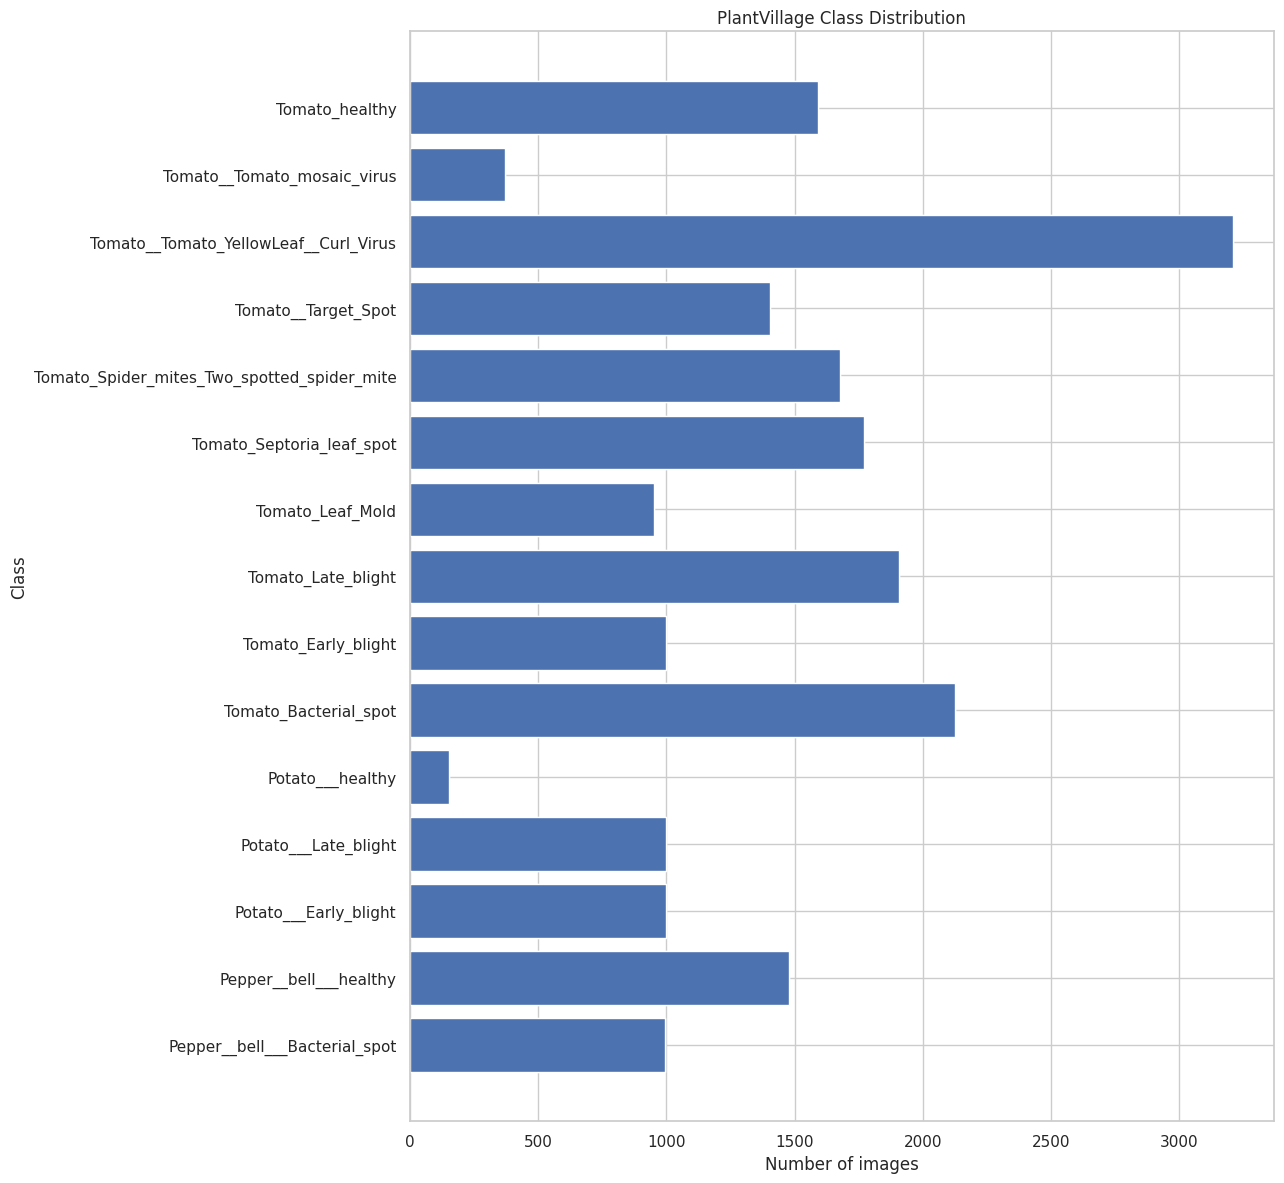

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

class_data = []

for path, count in image_dirs:
    class_data.append({
        "class_name": os.path.basename(path),
        "class_path": path,
        "image_count": count
    })

class_df = pd.DataFrame(class_data).sort_values("class_name")
class_df = class_df.reset_index(drop=True)

print("Detected classes:", len(class_df))
print("Total images:", class_df["image_count"].sum())
display(class_df)

plt.figure(figsize=(13, max(6, len(class_df) * 0.4)))
plt.barh(class_df["class_name"], class_df["image_count"])
plt.xlabel("Number of images")
plt.ylabel("Class")
plt.title("PlantVillage Class Distribution")
plt.tight_layout()
plt.show()


# DATA CLEANING

## DATASET ROOT

> A path that shows where our dataset is located



In [ ]:
DATASET_ROOT = Path("/content/PlantVillage/PlantVillage")

In [ ]:
assert DATASET_ROOT.exists(), (
    f"Dataset directory does not exist: {DATASET_ROOT}\n"
    "Please correct DATASET_ROOT before continuing."
)

print("Dataset root:", DATASET_ROOT)
print("\nTop-level contents:")

for item in sorted(DATASET_ROOT.iterdir()):
    if item.is_dir():
        print(f"[DIR]  {item.name}")
    else:
        print(f"[FILE] {item.name}")

Dataset root: /content/PlantVillage/PlantVillage

Top-level contents:
[DIR]  Pepper__bell___Bacterial_spot
[DIR]  Pepper__bell___healthy
[DIR]  Potato___Early_blight
[DIR]  Potato___Late_blight
[DIR]  Potato___healthy
[DIR]  Tomato_Bacterial_spot
[DIR]  Tomato_Early_blight
[DIR]  Tomato_Late_blight
[DIR]  Tomato_Leaf_Mold
[DIR]  Tomato_Septoria_leaf_spot
[DIR]  Tomato_Spider_mites_Two_spotted_spider_mite
[DIR]  Tomato__Target_Spot
[DIR]  Tomato__Tomato_YellowLeaf__Curl_Virus
[DIR]  Tomato__Tomato_mosaic_virus
[DIR]  Tomato_healthy


In [ ]:
print("\nDirectory structure:")

for root, dirs, files in os.walk(DATASET_ROOT):
    depth = len(Path(root).relative_to(DATASET_ROOT).parts)

    if depth <= 2:
        print(
            "  " * depth,
            Path(root).name,
            f"({len(files)} files)"
        )


Directory structure:
 PlantVillage (0 files)
   Tomato_healthy (1591 files)
   Tomato_Leaf_Mold (952 files)
   Potato___Late_blight (1000 files)
   Potato___healthy (152 files)
   Pepper__bell___healthy (1478 files)
   Tomato__Tomato_mosaic_virus (373 files)
   Potato___Early_blight (1000 files)
   Tomato_Spider_mites_Two_spotted_spider_mite (1676 files)
   Tomato_Late_blight (1909 files)
   Tomato__Target_Spot (1404 files)
   Tomato_Early_blight (1000 files)
   Tomato_Bacterial_spot (2127 files)
   Tomato__Tomato_YellowLeaf__Curl_Virus (3209 files)
   Tomato_Septoria_leaf_spot (1771 files)
   Pepper__bell___Bacterial_spot (997 files)


## DATASET INVENTORY

> We create a Pandas DataFrame containing the image paths, class names, file extensions, image dimensions, colour modes, and file sizes.

> Total image files found: 20638
Number of classes: 15





In [ ]:
SUPPORTED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

records = []

for class_dir in sorted(DATASET_ROOT.iterdir()):

    if not class_dir.is_dir():
        continue

    # Ignore common metadata and version-control directories.
    if class_dir.name.startswith(".") or class_dir.name.startswith("__"):
        continue

    for image_path in class_dir.rglob("*"):

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            continue

        try:
            file_size = image_path.stat().st_size

            with Image.open(image_path) as img:
                width, height = img.size
                image_format = img.format
                colour_mode = img.mode
                img.verify()

            records.append({
                "image_path": str(image_path),
                "class_name": class_dir.name,
                "extension": image_path.suffix.lower(),
                "file_size_bytes": file_size,
                "width": width,
                "height": height,
                "image_format": image_format,
                "colour_mode": colour_mode,
                "image_valid": True,
                "error": None
            })

        except Exception as e:
            records.append({
                "image_path": str(image_path),
                "class_name": class_dir.name,
                "extension": image_path.suffix.lower(),
                "file_size_bytes": (
                    image_path.stat().st_size
                    if image_path.exists() else None
                ),
                "width": None,
                "height": None,
                "image_format": None,
                "colour_mode": None,
                "image_valid": False,
                "error": str(e)
            })

metadata_df = pd.DataFrame(records)

print("Total image files found:", len(metadata_df))

if metadata_df.empty:
    raise ValueError(
        "No images were found. Check DATASET_ROOT and the folder structure."
    )

print("Number of classes:", metadata_df["class_name"].nunique())

display(metadata_df.head())

Total image files found: 20638
Number of classes: 15


,image_path,class_name,extension,file_size_bytes,width,height,image_format,colour_mode,image_valid,error
0,/content/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,.jpg,16924,256,256,JPEG,RGB,True,None
1,/content/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,.jpg,16901,256,256,JPEG,RGB,True,None
2,/content/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,.jpg,17754,256,256,JPEG,RGB,True,None
3,/content/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,.jpg,14403,256,256,JPEG,RGB,True,None
4,/content/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,.jpg,20132,256,256,JPEG,RGB,True,None


## DATASET SUMMARY

> This summarises everything in our dataset after it has been cleaned.



In [ ]:
print("DATASET SUMMARY")
print("=" * 50)

print("Total files:", len(metadata_df))
print("Valid images:", metadata_df["image_valid"].sum())
print("Invalid images:", (~metadata_df["image_valid"]).sum())
print("Number of classes:", metadata_df["class_name"].nunique())

print("\nMissing values:")
display(metadata_df.isnull().sum().to_frame("missing_values"))

print("\nData types:")
display(metadata_df.dtypes.to_frame("data_type"))

print("\nNumerical summary:")
display(metadata_df.describe(include="all").T)

DATASET SUMMARY
Total files: 20638
Valid images: 20638
Invalid images: 0
Number of classes: 15

Missing values:


,missing_values
image_path,0
class_name,0
extension,0
file_size_bytes,0
width,0
height,0
image_format,0
colour_mode,0
image_valid,0
error,20638



Data types:


,data_type
image_path,object
class_name,object
extension,object
file_size_bytes,int64
width,int64
height,int64
image_format,object
colour_mode,object
image_valid,bool
error,object



Numerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
image_path,20638,20638,/content/PlantVillage/PlantVillage/Tomato_heal...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class_name,20638,15,Tomato__Tomato_YellowLeaf__Curl_Virus,3208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
extension,20638,3,.jpg,20636,NaN,NaN,NaN,NaN,NaN,NaN,NaN
file_size_bytes,20638.0,NaN,NaN,NaN,16582.552718,4611.936058,3440.0,13060.5,16999.5,19843.75,121652.0
width,20638.0,NaN,NaN,NaN,256.0,0.0,256.0,256.0,256.0,256.0,256.0
height,20638.0,NaN,NaN,NaN,256.0,0.0,256.0,256.0,256.0,256.0,256.0
image_format,20638,2,JPEG,20637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
colour_mode,20638,2,RGB,20637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_valid,20638,1,True,20638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Detect duplicate files

> we further removed duplicate files after the first removal of about 20,000 duplicates



In [ ]:
def sha256_file(filepath, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(filepath, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


valid_paths = metadata_df.loc[
    metadata_df["image_valid"],
    "image_path"
].tolist()

hash_records = []

for filepath in valid_paths:
    try:
        hash_records.append({
            "image_path": filepath,
            "sha256": sha256_file(filepath)
        })
    except Exception as e:
        print(f"Hashing failed for {filepath}: {e}")

hash_df = pd.DataFrame(hash_records)

if not hash_df.empty:
    duplicate_mask = hash_df.duplicated(
        subset="sha256",
        keep="first"
    )

    duplicate_paths = set(
        hash_df.loc[duplicate_mask, "image_path"]
    )
else:
    duplicate_paths = set()

print("Exact duplicate files:", len(duplicate_paths))

Exact duplicate files: 14


## Remove invalid files and exact duplicates

> Invalid files and duplicates were removed



In [ ]:
clean_df = metadata_df[
    metadata_df["image_valid"]
].copy()

clean_df = clean_df[
    ~clean_df["image_path"].isin(duplicate_paths)
].copy()

clean_df = clean_df[
    (clean_df["width"] > 0) &
    (clean_df["height"] > 0) &
    (clean_df["file_size_bytes"] > 0)
].copy()

clean_df.reset_index(drop=True, inplace=True)

print("Original image files:", len(metadata_df))
print("Invalid files:", (~metadata_df["image_valid"]).sum())
print("Exact duplicate files removed:", len(duplicate_paths))
print("Cleaned image count:", len(clean_df))
print("Remaining classes:", clean_df["class_name"].nunique())

Original image files: 20638
Invalid files: 0
Exact duplicate files removed: 14
Cleaned image count: 20624
Remaining classes: 15


## Inspect class labels and counts

> We check class consistency



In [ ]:
class_counts = (
    clean_df["class_name"]
    .value_counts()
    .sort_values(ascending=False)
)

class_df = class_counts.rename_axis(
    "class_name"
).reset_index(name="image_count")

display(class_df)

print("\nNumber of classes:", len(class_df))
print("Smallest class size:", class_df["image_count"].min())
print("Largest class size:", class_df["image_count"].max())
print("Average images per class:", round(class_df["image_count"].mean(), 2))

,class_name,image_count
0,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
1,Tomato_Bacterial_spot,2127
2,Tomato_Late_blight,1901
3,Tomato_Septoria_leaf_spot,1771
4,Tomato_Spider_mites_Two_spotted_spider_mite,1676
5,Tomato_healthy,1585
6,Pepper__bell___healthy,1478
7,Tomato__Target_Spot,1404
8,Potato___Early_blight,1000
9,Potato___Late_blight,1000



Number of classes: 15
Smallest class size: 152
Largest class size: 3208
Average images per class: 1374.93


# Exploratory Data Analysis (EDA)

> The EDA describe the dataset and reveal patterns that may affect the model because PlantVillage is an image dataset, our EDA include image-specific visualisations in addition to conventional numerical and categorical plots.



## Class distribution

> Bar chart of disease classes, this graph reveals whether some classes have significantly more images than others.



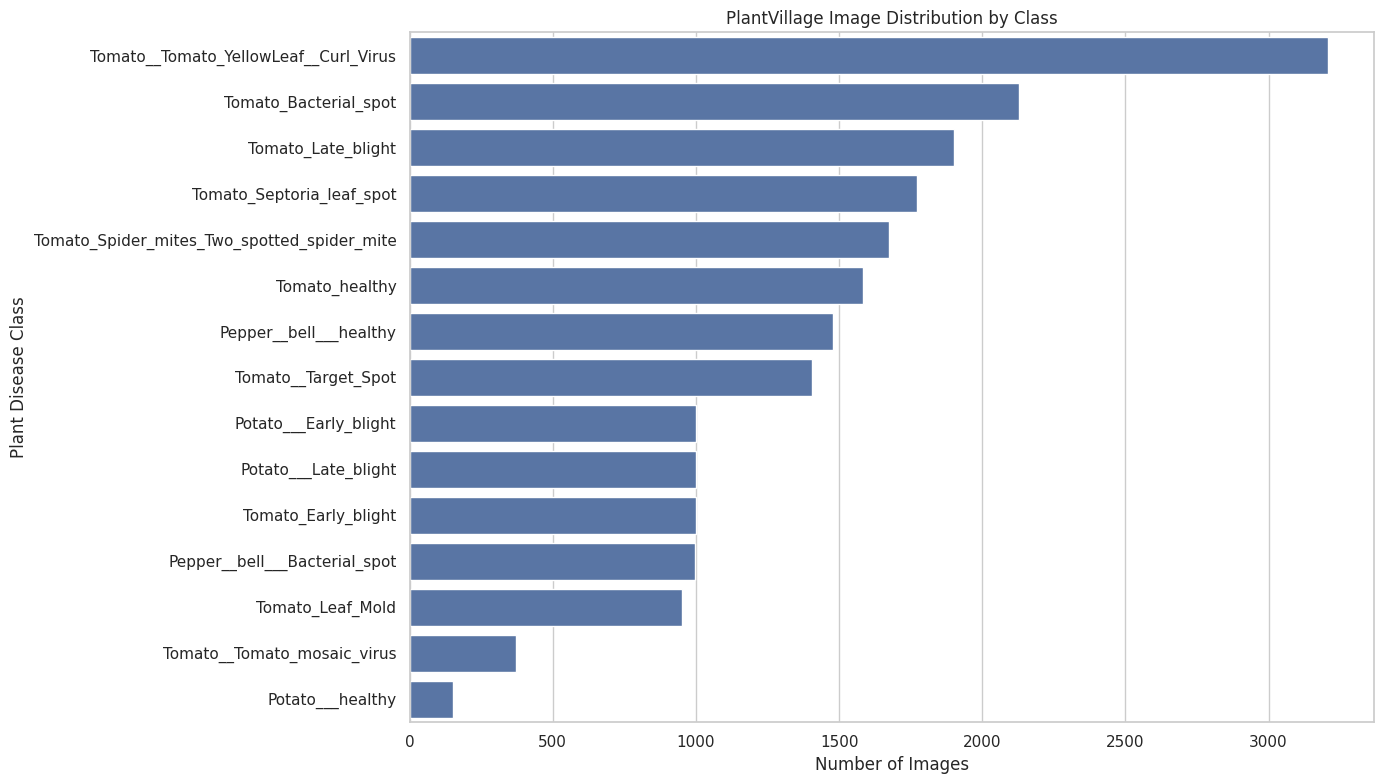

In [ ]:
plt.figure(figsize=(14, max(8, len(class_df) * 0.28)))

sns.barplot(
    data=class_df,
    x="image_count",
    y="class_name"
)

plt.title("PlantVillage Image Distribution by Class")
plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.tight_layout()
plt.show()

## Numerical distribution plots

> Image dimensions and file sizes, unusual dimensions, extreme aspect ratios, or unexpectedly small files may indicate damaged or a typical images.



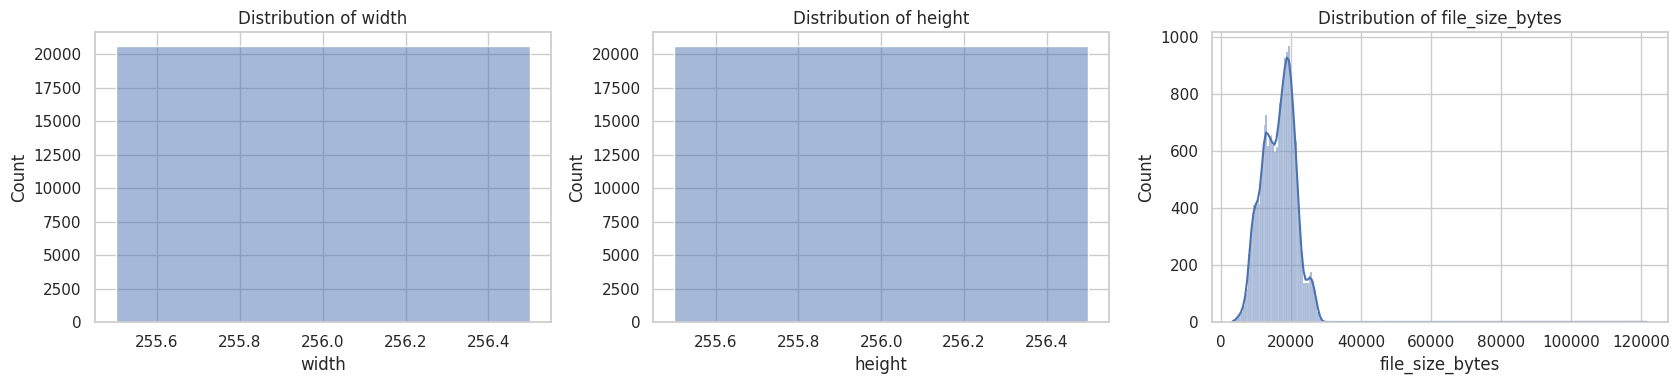

In [ ]:
numeric_columns = [
    "width",
    "height",
    "file_size_bytes"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4)
)

for ax, column in zip(axes, numeric_columns):

    values = clean_df[column].dropna()

    sns.histplot(
        values,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

## Categorical distributions

> File extensions and colour modes, we convert images to RGB when loading them, so grayscale or RGBA images can be handled consistently.



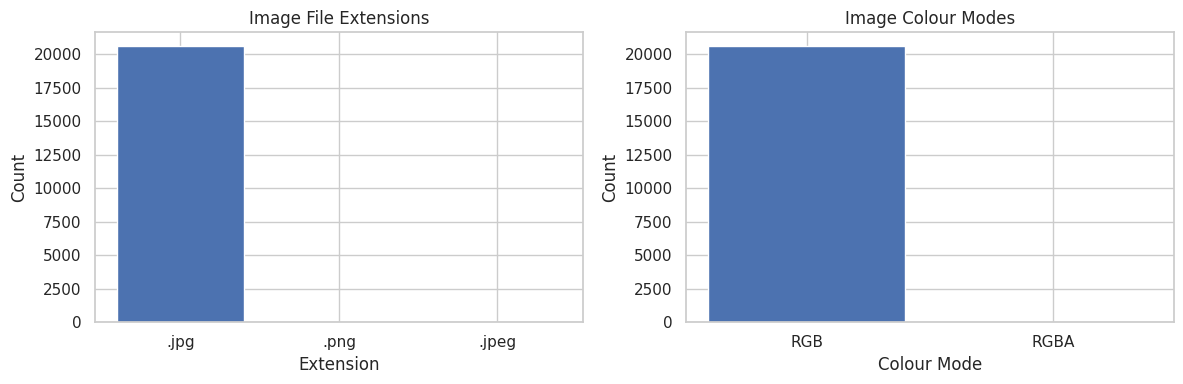

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

extension_counts = clean_df["extension"].value_counts()

axes[0].bar(
    extension_counts.index,
    extension_counts.values
)

axes[0].set_title("Image File Extensions")
axes[0].set_xlabel("Extension")
axes[0].set_ylabel("Count")

mode_counts = clean_df["colour_mode"].value_counts()

axes[1].bar(
    mode_counts.index,
    mode_counts.values
)

axes[1].set_title("Image Colour Modes")
axes[1].set_xlabel("Colour Mode")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

## Visualise representative images

> Some sample images displayed



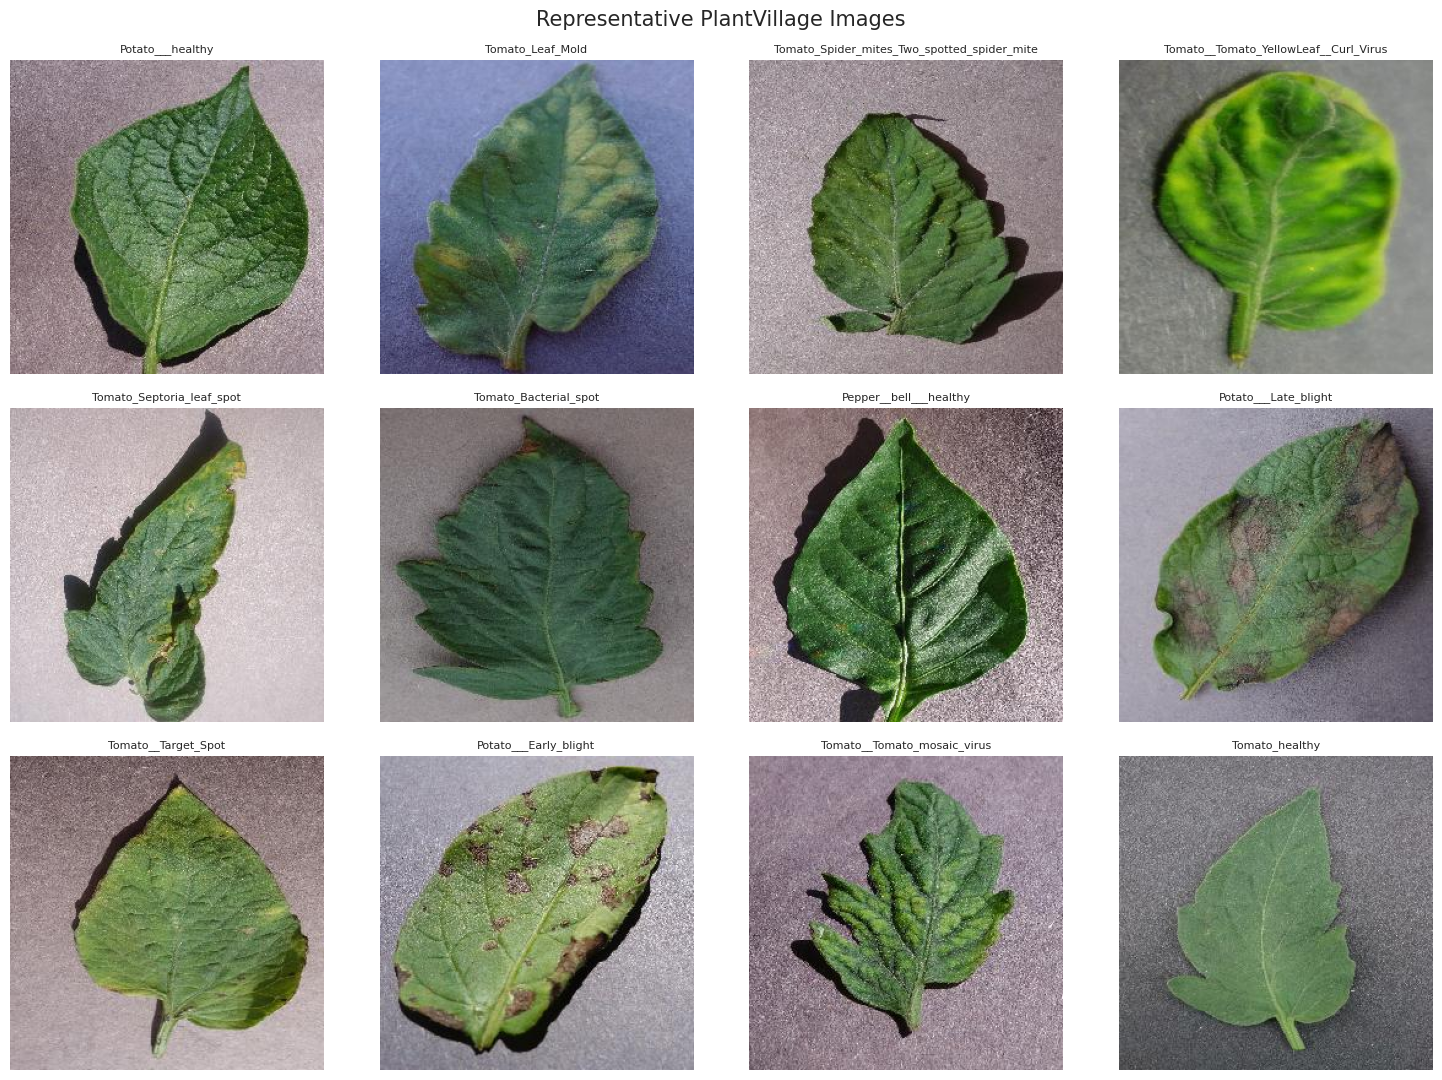

In [ ]:
sample_classes = sorted(
    clean_df["class_name"].unique()
)

number_to_show = min(12, len(sample_classes))

selected_classes = random.sample(
    sample_classes,
    number_to_show
)

fig, axes = plt.subplots(
    3, 4,
    figsize=(15, 11)
)

axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, class_name in zip(axes, selected_classes):

    image_path = clean_df.loc[
        clean_df["class_name"] == class_name,
        "image_path"
    ].iloc[0]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name, fontsize=8)
    ax.axis("off")

plt.suptitle(
    "Representative PlantVillage Images",
    fontsize=15
)

plt.tight_layout()
plt.show()

## Correlation heatmap

> This heatmap shows linear relationships among simple image characteristics.
For example, average brightness may correlate with average RGB intensities. Width and height may also be associated if images use standardised dimensions.



## DEFINE SAMPLE PATHS

In [ ]:

import os
import glob
import random

# Update this path if your dataset is stored elsewhere
DATASET_DIR = "/content/PlantVillage/PlantVillage"

# Find all image files recursively
image_extensions = ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG")

all_image_paths = []

for ext in image_extensions:
    all_image_paths.extend(
        glob.glob(os.path.join(DATASET_DIR, "**", ext), recursive=True)
    )

# Remove duplicate paths and sort
all_image_paths = sorted(set(all_image_paths))

print("Total images found:", len(all_image_paths))

# Check that images were found
if not all_image_paths:
    raise FileNotFoundError(
        f"No images found in {DATASET_DIR}. Check your dataset path."
    )

# Sample up to 500 images for EDA feature extraction
random.seed(42)
sample_size = min(500, len(all_image_paths))
sample_paths = random.sample(all_image_paths, sample_size)

print("Sample images selected:", len(sample_paths))
print("Example image path:", sample_paths[0])


Total images found: 20638
Sample images selected: 500
Example image path: /content/PlantVillage/PlantVillage/Potato___Late_blight/2d8cbe58-280e-4c93-9b06-26f4279eb4d8___RS_LB 2855.JPG


In [ ]:
feature_records = []

for filepath in sample_paths:

    try:
        with Image.open(filepath) as img:

            img = img.convert("RGB")
            img.thumbnail((128, 128))

            arr = np.asarray(
                img,
                dtype=np.float32
            ) / 255.0

            feature_records.append({
                "image_path": filepath,
                "mean_red": arr[:, :, 0].mean(),
                "mean_green": arr[:, :, 1].mean(),
                "mean_blue": arr[:, :, 2].mean(),
                "brightness": arr.mean(),
                "contrast": arr.std(),
                "width": Image.open(filepath).width,
                "height": Image.open(filepath).height
            })

    except Exception:
        continue

feature_df = pd.DataFrame(feature_records)

display(feature_df.head())

,image_path,mean_red,mean_green,mean_blue,brightness,contrast,width,height
0,/content/PlantVillage/PlantVillage/Potato___La...,0.412119,0.429017,0.395995,0.412377,0.140608,256,256
1,/content/PlantVillage/PlantVillage/Pepper__bel...,0.577700,0.562831,0.454527,0.531686,0.200456,256,256
2,/content/PlantVillage/PlantVillage/Tomato_Late...,0.444003,0.461353,0.405555,0.436970,0.253860,256,256
3,/content/PlantVillage/PlantVillage/Tomato_Late...,0.514475,0.515359,0.473028,0.500954,0.272429,256,256
4,/content/PlantVillage/PlantVillage/Tomato_Earl...,0.387894,0.435082,0.392918,0.405298,0.146719,256,256


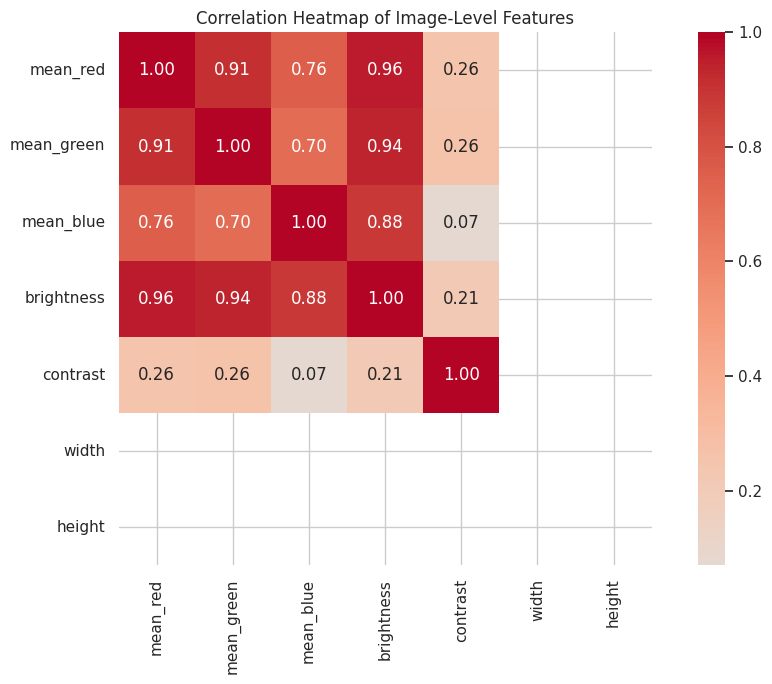

In [ ]:
correlation_columns = [
    "mean_red",
    "mean_green",
    "mean_blue",
    "brightness",
    "contrast",
    "width",
    "height"
]

correlation_matrix = feature_df[
    correlation_columns
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    square=True
)

plt.title("Correlation Heatmap of Image-Level Features")
plt.tight_layout()
plt.show()

# DATA PREPROCESSING

## Prepare the training, validation, and testing sets

> Stratified splitting aims to preserve each class's relative frequency across the three sets.

> We will use a 70:15:15 split.

> Dataset	Percentage	Purpose
Training	70%	Learn model parameters
Validation	15%	Monitor performance and tune training
Testing	15%	Final, independent evaluation







### Validate the class counts

> We ensure that all classes have at least three images.



In [ ]:
class_counts = clean_df["class_name"].value_counts()

insufficient_classes = class_counts[
    class_counts < 3
]

if len(insufficient_classes) > 0:
    raise ValueError(
        "Some classes have fewer than three images. "
        "A reliable stratified three-way split is not possible "
        "for these classes:\n"
        f"{insufficient_classes.to_dict()}"
    )

print("All classes have at least three images.")

All classes have at least three images.


#### Create the splits

> we then created the splits based on the ratio



In [ ]:
train_df, temporary_df = train_test_split(
    clean_df,
    test_size=0.30,
    random_state=SEED,
    stratify=clean_df["class_name"]
)

validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_df["class_name"]
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Testing images:", len(test_df))

print("\nSplit proportions:")

total_images = (
    len(train_df) +
    len(validation_df) +
    len(test_df)
)

print(f"Training:   {len(train_df) / total_images:.2%}")
print(f"Validation: {len(validation_df) / total_images:.2%}")
print(f"Testing:    {len(test_df) / total_images:.2%}")

Training images: 14436
Validation images: 3094
Testing images: 3094

Split proportions:
Training:   70.00%
Validation: 15.00%
Testing:    15.00%


#### Verify class representation

> Every class is represented in all three sets.



In [ ]:
train_classes = set(train_df["class_name"])
validation_classes = set(validation_df["class_name"])
test_classes = set(test_df["class_name"])

all_classes = set(clean_df["class_name"])

assert train_classes == all_classes
assert validation_classes == all_classes
assert test_classes == all_classes

print("Every class is represented in all three sets.")

Every class is represented in all three sets.


#### Visualise the split distributions

> Bar chart that shows the split distribution in the ratio 70:15:15



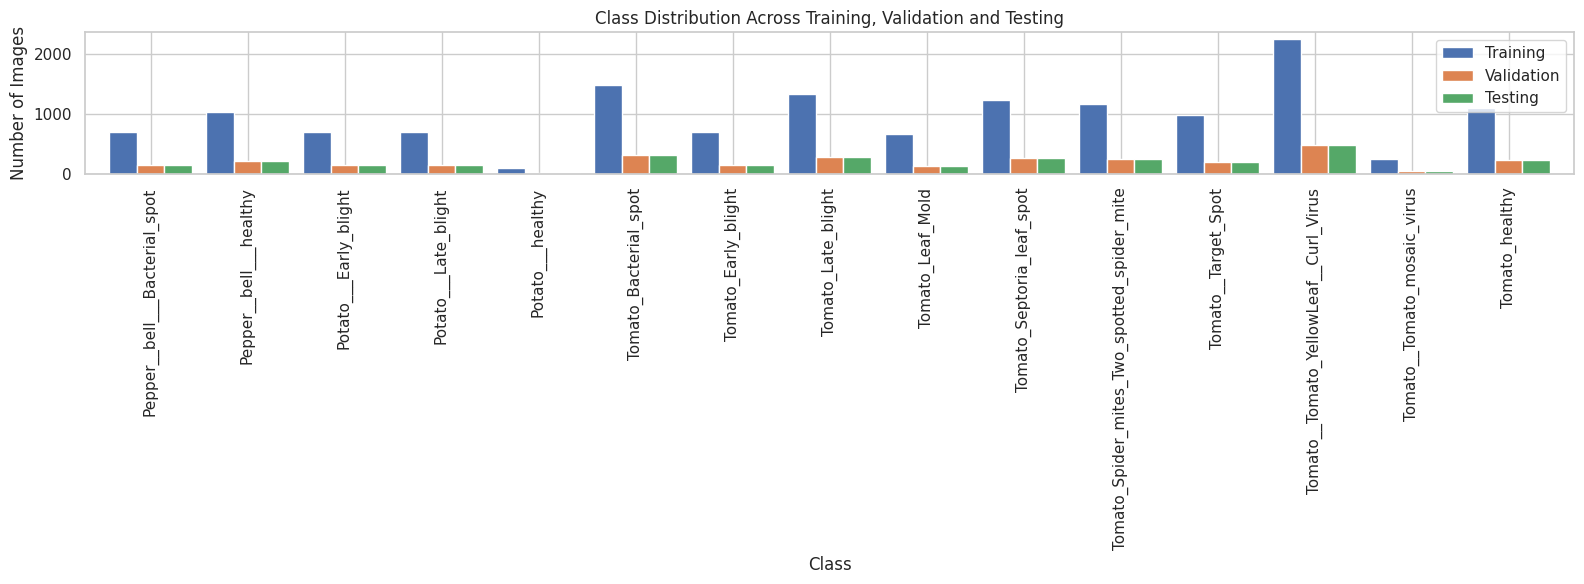

In [ ]:
train_counts = train_df["class_name"].value_counts()
validation_counts = validation_df["class_name"].value_counts()
test_counts = test_df["class_name"].value_counts()

split_comparison = pd.DataFrame({
    "Training": train_counts,
    "Validation": validation_counts,
    "Testing": test_counts
}).fillna(0)

split_comparison.plot(
    kind="bar",
    figsize=(16, 6),
    width=0.85
)

plt.title("Class Distribution Across Training, Validation and Testing")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### Create a consistent class mapping

> VGG16 was designed for 224 × 224 RGB inputs in its standard ImageNet configuration, so there should be consistency in the class mapping



In [ ]:
class_names = sorted(
    clean_df["class_name"].unique()
)

NUM_CLASSES = len(class_names)

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("Number of classes:", NUM_CLASSES)

print("\nClass mapping:")

for class_name, index in class_to_index.items():
    print(f"{index:3d} -> {class_name}")

Number of classes: 15

Class mapping:
  0 -> Pepper__bell___Bacterial_spot
  1 -> Pepper__bell___healthy
  2 -> Potato___Early_blight
  3 -> Potato___Late_blight
  4 -> Potato___healthy
  5 -> Tomato_Bacterial_spot
  6 -> Tomato_Early_blight
  7 -> Tomato_Late_blight
  8 -> Tomato_Leaf_Mold
  9 -> Tomato_Septoria_leaf_spot
 10 -> Tomato_Spider_mites_Two_spotted_spider_mite
 11 -> Tomato__Target_Spot
 12 -> Tomato__Tomato_YellowLeaf__Curl_Virus
 13 -> Tomato__Tomato_mosaic_virus
 14 -> Tomato_healthy


#### Choose image size and batch size

> A batch size of 32 is a reasonable starting point



In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 224
Batch size: 32


#### Create TensorFlow datasets

> Tensorflow dataset was created



In [ ]:
def dataframe_to_tf_dataset(
    dataframe,
    training=False
):

    paths = dataframe["image_path"].to_numpy()

    labels = dataframe["class_name"].map(
        class_to_index
    ).to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):

        image_bytes = tf.io.read_file(path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(
            image,
            [IMG_SIZE, IMG_SIZE],
            method="bilinear"
        )

        image = tf.cast(image, tf.float32)

        image = preprocess_input(image)

        return image, label

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

## Build the datasets

> since we are using the package called Tensorflow, we built our dataset



In [ ]:
train_ds = dataframe_to_tf_dataset(
    train_df,
    training=True
)

validation_ds = dataframe_to_tf_dataset(
    validation_df
)

test_ds = dataframe_to_tf_dataset(
    test_df
)

print("TensorFlow datasets created.")

TensorFlow datasets created.


## Verify the image pipeline

> This shows the structure of our images



In [ ]:
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)

    print("Minimum preprocessed value:", tf.reduce_min(images).numpy())
    print("Maximum preprocessed value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>
Minimum preprocessed value: -123.68
Maximum preprocessed value: 140.28995


## Apply data augmentation

> Data augmentation creates varied training examples from existing images.



In [ ]:
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            "horizontal"
        ),

        layers.RandomRotation(
            factor=0.08
        ),

        layers.RandomZoom(
            height_factor=0.10,
            width_factor=0.10
        ),

        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        )
    ],
    name="data_augmentation"
)

# Build the VGG16 model

> The new classification head use global average pooling, a dense layer, dropout, and a softmax output.
Global average pooling provides a compact representation of the convolutional features without the very large parameter count associated with flattening the entire feature map.

> Why this architecture?
- Pretrained VGG16: provides useful low-level and mid-level visual representations.
- Global average pooling: reduces the number of trainable parameters.
- Batch normalisation: helps stabilise the dense feature representation.
- Dense layers: learn decision boundaries for the plant disease classes.
- Dropout and L2 regularisation: help reduce overfitting.
- Softmax: produces class probabilities.





## Construct the model

> We set our hyperparameters at this point.



In [ ]:
tf.keras.backend.clear_session()

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="input_image"
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.BatchNormalization(
    name="feature_batch_normalization"
)(x)

x = layers.Dense(
    512,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="dense_512"
)(x)

x = layers.Dropout(
    0.40,
    name="dropout_1"
)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="dense_256"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout_2"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="disease_predictions"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="PlantVillage_VGG16"
)

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "PlantVillage_VGG16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_batch_normalization     │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_predictions (Dense)     │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,114,575 (57.66 MB)

 Trainable params: 398,863 (1.52 MB)

 Non-trainable params: 14,715,712 (56.14 MB)

## Compile the model

> We configure the optimiser and loss



In [ ]:
INITIAL_LEARNING_RATE = 1e-3

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


## Define training callbacks

> During this stage, VGG16's pretrained convolutional layers remain frozen. Only the new classification head is trained.
We use early stopping, learning-rate reduction, and checkpointing.



In [ ]:
OUTPUT_DIR = Path("/content/plantvillage_vgg16_outputs")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_HEAD_PATH = (
    OUTPUT_DIR / "vgg16_best_transfer_learning.keras"
)

HEAD_LOG_PATH = (
    OUTPUT_DIR / "transfer_learning_history.csv"
)

head_callbacks = [

    ModelCheckpoint(
        filepath=str(BEST_HEAD_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    CSVLogger(
        str(HEAD_LOG_PATH)
    )
]

## Train the model

> Fifteen is the maximum number of epochs for this stage. Early stopping may terminate training sooner.
If our runtime runs out of GPU time, the best checkpoint is saved before ending the session.



In [ ]:
INITIAL_EPOCHS = 15

history_head = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=INITIAL_EPOCHS,
    callbacks=head_callbacks,
    verbose=1
)

Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.6014 - loss: 1.3779
Epoch 1: val_loss improved from None to 0.46955, saving model to /content/plantvillage_vgg16_outputs/vgg16_best_transfer_learning.keras

Epoch 1: finished saving model to /content/plantvillage_vgg16_outputs/vgg16_best_transfer_learning.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 88s 177ms/step - accuracy: 0.7218 - loss: 0.9622 - val_accuracy: 0.8801 - val_loss: 0.4696 - learning_rate: 0.0010
Epoch 2/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.8397 - loss: 0.5913
Epoch 2: val_loss improved from 0.46955 to 0.45419, saving model to /content/plantvillage_vgg16_outputs/vgg16_best_transfer_learning.keras

Epoch 2: finished saving model to /content/plantvillage_vgg16_outputs/vgg16_best_transfer_learning.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 88s 194ms/step - accuracy: 0.8472 - loss: 0.5700 - val_accuracy: 0.8878 - val_loss: 0.4542 - learning_rate: 0.0010
Epoch 3/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/

## Plot accuracy and loss

> Training accuracy alone is insufficient to assess model quality. We must compare training and validation metrics.

> Pattern	interpretation
Training and validation accuracy both increase	The model is learning useful features.
Training accuracy rises but validation accuracy stagnates	Possible overfitting.
Validation loss rises while training loss falls	A common overfitting pattern.
Both accuracies remain low	Possible underfitting, preprocessing problems, or insufficient training.
Validation accuracy fluctuates sharply	The validation set may be small, classes may be imbalanced, or training may be unstable.





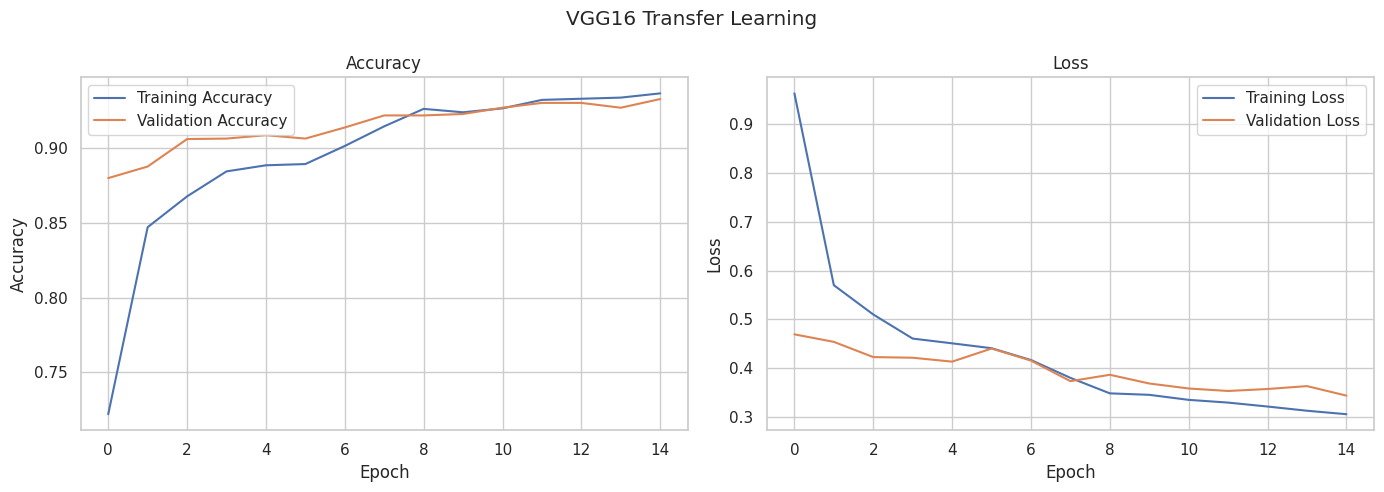

In [ ]:
def plot_training_history(history, title):

    history_df = pd.DataFrame(history.history)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5)
    )

    axes[0].plot(
        history_df["accuracy"],
        label="Training Accuracy"
    )

    axes[0].plot(
        history_df["val_accuracy"],
        label="Validation Accuracy"
    )

    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(
        history_df["loss"],
        label="Training Loss"
    )

    axes[1].plot(
        history_df["val_loss"],
        label="Validation Loss"
    )

    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_training_history(
    history_head,
    "VGG16 Transfer Learning"
)

# Fine-tune the upper VGG16 layers

> Transfer learning often benefits from adapting some pretrained convolutional layers to the target dataset.
However, unfreezing every layer immediately can damage useful pretrained representations and increase the risk of overfitting.
We unfreeze the final VGG16 convolutional block while keeping earlier blocks frozen.



## Configure fine-tuning

In [ ]:
base_model.trainable = True

# Keep earlier convolutional blocks frozen.
for layer in base_model.layers:
    layer.trainable = False

# Fine-tune the final convolutional block.
for layer in base_model.layers:
    if layer.name.startswith("block5_"):
        layer.trainable = True

print("Trainable VGG16 layers:")

for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

Trainable VGG16 layers:
block5_conv1
block5_conv2
block5_conv3
block5_pool


## Recompile with a lower learning rate

> After changing trainability, we must recompile the model.



In [ ]:
FINE_TUNE_LEARNING_RATE = 1e-5

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


## Define fine-tuning callbacks

In [ ]:
BEST_FINE_TUNE_PATH = (
    OUTPUT_DIR / "vgg16_best_fine_tuned.keras"
)

FINE_TUNE_LOG_PATH = (
    OUTPUT_DIR / "fine_tuning_history.csv"
)

fine_tune_callbacks = [

    ModelCheckpoint(
        filepath=str(BEST_FINE_TUNE_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-8,
        verbose=1
    ),

    CSVLogger(
        str(FINE_TUNE_LOG_PATH)
    )
]

## Fine-tune the model

> 10 Epoch was set this time. Early stopping will end training when validation loss no longer improves sufficiently.



In [ ]:
FINE_TUNE_EPOCHS = 10

history_fine = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks,
    verbose=1
)

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.9499 - loss: 0.2669
Epoch 1: val_loss improved from None to 0.27746, saving model to /content/plantvillage_vgg16_outputs/vgg16_best_fine_tuned.keras

Epoch 1: finished saving model to /content/plantvillage_vgg16_outputs/vgg16_best_fine_tuned.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 101s 214ms/step - accuracy: 0.9550 - loss: 0.2555 - val_accuracy: 0.9541 - val_loss: 0.2775 - learning_rate: 1.0000e-05
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.9674 - loss: 0.2155
Epoch 2: val_loss improved from 0.27746 to 0.25179, saving model to /content/plantvillage_vgg16_outputs/vgg16_best_fine_tuned.keras

Epoch 2: finished saving model to /content/plantvillage_vgg16_outputs/vgg16_best_fine_tuned.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 99s 218ms/step - accuracy: 0.9689 - loss: 0.2160 - val_accuracy: 0.9657 - val_loss: 0.2518 - learning_rate: 1.0000e-05
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.

## Plot fine-tuning history

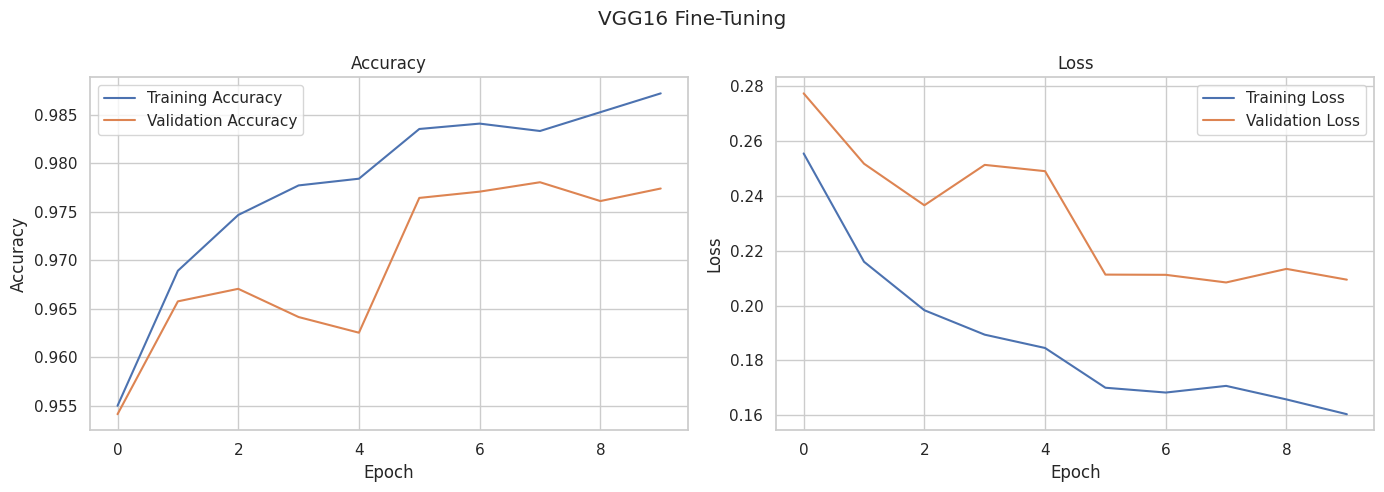

In [ ]:
plot_training_history(
    history_fine,
    "VGG16 Fine-Tuning"
)

In [ ]:
# Check common model variable names
for name in ["best_model", "model", "vgg16_model", "fine_tuned_model"]:
    if name in globals():
        print(f"{name} exists:", type(globals()[name]))


model exists: <class 'keras.src.models.functional.Functional'>


## Generate test predictions

> We then evaluate our model performance



In [ ]:
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

probabilities = model.predict(
    test_ds,
    verbose=1
)

y_pred = np.argmax(
    probabilities,
    axis=1
)

assert len(y_true) == len(y_pred)

print("Number of test examples:", len(y_true))
print("Number of predictions:", len(y_pred))

97/97 ━━━━━━━━━━━━━━━━━━━━ 14s 141ms/step
Number of test examples: 3094
Number of predictions: 3094


## Calculate summary metrics

In [ ]:
metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),

    "Balanced Accuracy": balanced_accuracy_score(
        y_true,
        y_pred
    ),

    "Macro Precision": precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro F1-score": f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    ),

    "Weighted Precision": precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    ),

    "Weighted Recall": recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    ),

    "Weighted F1-score": f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

display(
    metrics_df.style.format({
        "Score": "{:.4f}"
    })
)

,Metric,Score
0,Accuracy,0.9783
1,Balanced Accuracy,0.9725
2,Macro Precision,0.9797
3,Macro Recall,0.9725
4,Macro F1-score,0.9753
5,Weighted Precision,0.9792
6,Weighted Recall,0.9783
7,Weighted F1-score,0.9782


## Classification report

> This is the general report of the classification from each class



In [ ]:
class_report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    class_report
).T

display(
    report_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

print("Classification report saved.")

,precision,recall,f1-score,support
Pepper__bell___Bacterial_spot,0.9868,1.0000,0.9934,150
Pepper__bell___healthy,1.0000,0.9955,0.9977,221
Potato___Early_blight,1.0000,1.0000,1.0000,150
Potato___Late_blight,0.9866,0.9800,0.9833,150
Potato___healthy,0.9565,0.9565,0.9565,23
Tomato_Bacterial_spot,0.9608,1.0000,0.9800,319
Tomato_Early_blight,1.0000,0.8467,0.9170,150
Tomato_Late_blight,0.9759,0.9965,0.9861,285
Tomato_Leaf_Mold,1.0000,0.9580,0.9786,143
Tomato_Septoria_leaf_spot,0.9741,0.9925,0.9832,265


Classification report saved.


## Confusion matrix

> The confusion matrix reveals which diseases the model confuses with one another.



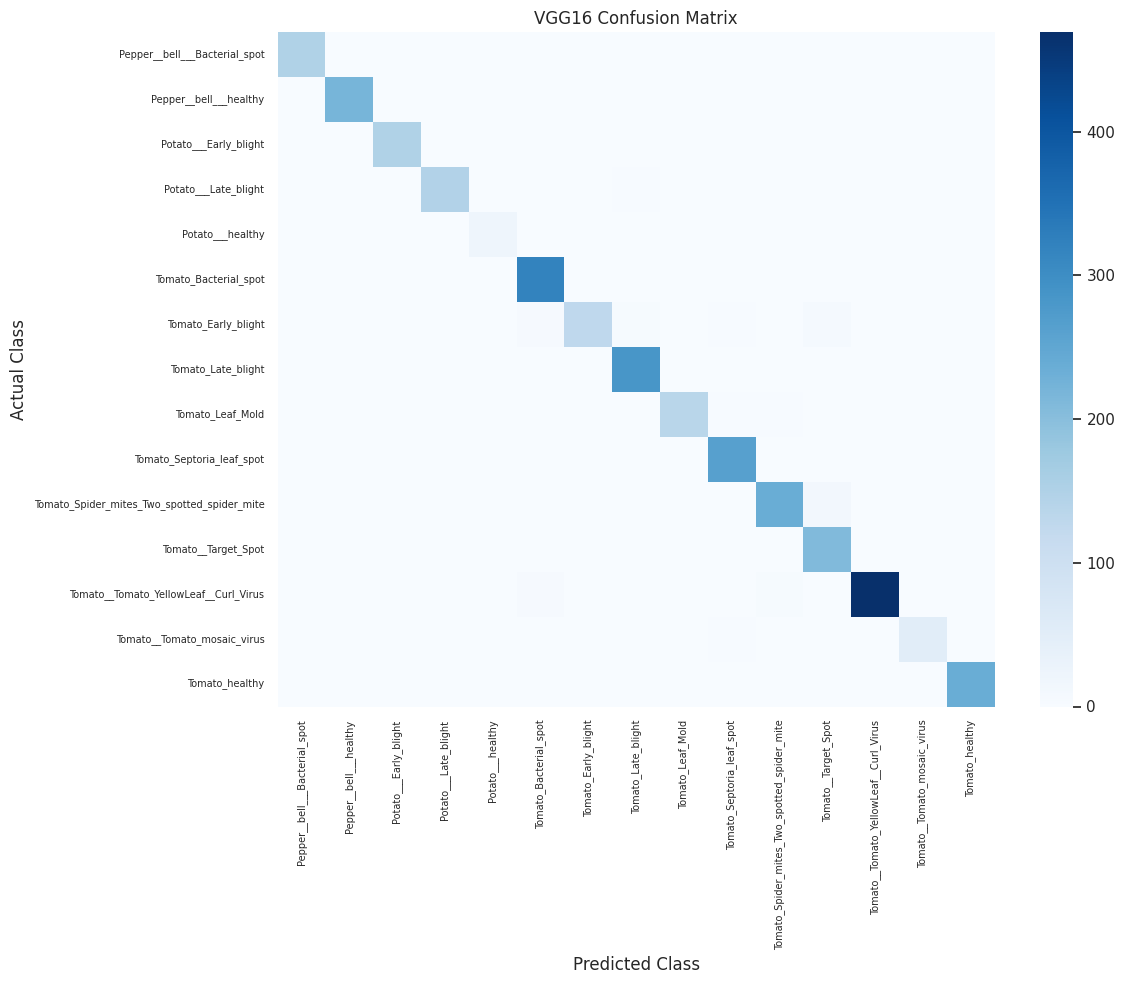

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(
    figsize=(
        max(12, NUM_CLASSES * 0.45),
        max(10, NUM_CLASSES * 0.40)
    )
)

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)

plt.title("VGG16 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    rotation=90,
    fontsize=7
)

plt.yticks(
    rotation=0,
    fontsize=7
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()